This notebook cleans and vectorizes SMS messages with TF-IDF and trains a Multinomial Naive Bayes spam classifier. It reaches 95.16% accuracy and 100% precision on the test set, with a recall of 63.76% (F1-score 0.7787). It also inspects the words the model learned as the strongest spam/ham indicators and tests the model on a few custom messages.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

In [2]:
#Task1

spam_df = pd.read_csv("/kaggle/input/sms-spam-collection-dataset/spam.csv", encoding="latin-1")[["v1", "v2"]]
spam_df.columns = ["label", "message"]

print("Spam shape:", spam_df.shape)
display(spam_df.head())

print("\nClass counts:")
print(spam_df["label"].value_counts())
print("\nClass percentages:")
print(spam_df["label"].value_counts(normalize=True) * 100)

Spam shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Class counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Class percentages:
label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


In [3]:
#Task3

spam_df["message_clean"] = spam_df["message"].str.lower().str.replace(r"[^a-z0-9\s]", "", regex=True)

spam_df[["message", "message_clean"]].head()

,message,message_clean
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...


In [4]:
#Task4

y_spam = spam_df["label"].map({"ham": 0, "spam": 1})

X_train_msg, X_test_msg, y_train_spam, y_test_spam = train_test_split(
    spam_df["message_clean"], y_spam,
    test_size=0.20,
    random_state=42,
    stratify=y_spam
)

spam_vectorizer = TfidfVectorizer()
X_train_spam_vec = spam_vectorizer.fit_transform(X_train_msg)
X_test_spam_vec = spam_vectorizer.transform(X_test_msg)

print("Vocabulary size:", len(spam_vectorizer.get_feature_names_out()))
print("X_train_spam_vec shape:", X_train_spam_vec.shape)
print("X_test_spam_vec shape:", X_test_spam_vec.shape)

Vocabulary size: 8343
X_train_spam_vec shape: (4457, 8343)
X_test_spam_vec shape: (1115, 8343)


,Metric,Naive Bayes
0,Accuracy,0.951570
1,Precision,1.000000
2,Recall,0.637584
3,F1-Score,0.778689


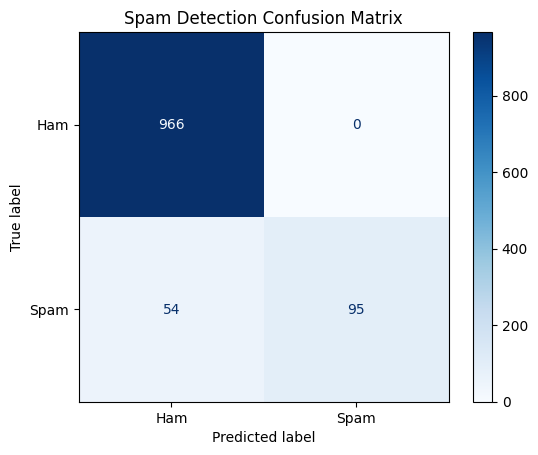

In [5]:
#Task5

nb_spam = MultinomialNB()
nb_spam.fit(X_train_spam_vec, y_train_spam)

spam_test_pred = nb_spam.predict(X_test_spam_vec)

spam_accuracy = accuracy_score(y_test_spam, spam_test_pred)
spam_precision = precision_score(y_test_spam, spam_test_pred)
spam_recall = recall_score(y_test_spam, spam_test_pred)
spam_f1 = f1_score(y_test_spam, spam_test_pred)

spam_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Naive Bayes": [spam_accuracy, spam_precision, spam_recall, spam_f1]
})

display(spam_results)

ConfusionMatrixDisplay.from_predictions(y_test_spam, spam_test_pred, display_labels=["Ham", "Spam"], cmap="Blues")
plt.title("Spam Detection Confusion Matrix")
plt.show()

In [6]:
#Task7

log_prob = nb_spam.feature_log_prob_
diff = log_prob[1] - log_prob[0]
feature_names = spam_vectorizer.get_feature_names_out()

top_spam_idx = np.argsort(diff)[-15:][::-1]
top_ham_idx = np.argsort(diff)[:15]

top_spam_words = pd.DataFrame({
    "Word": feature_names[top_spam_idx],
    "Log-Prob Difference (spam - ham)": diff[top_spam_idx]
})

top_ham_words = pd.DataFrame({
    "Word": feature_names[top_ham_idx],
    "Log-Prob Difference (spam - ham)": diff[top_ham_idx]
})

print("Top 15 words most associated with SPAM:")
display(top_spam_words)

print("Top 15 words most associated with HAM:")
display(top_ham_words)

Top 15 words most associated with SPAM:


,Word,Log-Prob Difference (spam - ham)
0,claim,3.457264
1,prize,3.235886
2,won,3.113645
3,urgent,2.785050
4,guaranteed,2.776270
5,nokia,2.740405
6,500,2.734719
7,1000,2.721418
8,tone,2.684464
9,18,2.660018


Top 15 words most associated with HAM:


,Word,Log-Prob Difference (spam - ham)
0,ill,-3.339564
1,my,-3.243134
2,ltgt,-3.156736
3,ok,-3.125576
4,later,-3.047391
5,lor,-2.983769
6,im,-2.911841
7,come,-2.875702
8,home,-2.850535
9,but,-2.843229


In [7]:
#Task8

my_messages = [
    "Congratulations! You have WON a free prize, claim now by calling this number",
    "Hey, are we still meeting for lunch tomorrow?",
    "URGENT: your account has been suspended, click the link to verify",
]

my_messages_clean = [re.sub(r"[^a-z0-9\s]", "", m.lower()) for m in my_messages]
my_messages_vec = spam_vectorizer.transform(my_messages_clean)
my_predictions = nb_spam.predict(my_messages_vec)

for msg, pred in zip(my_messages, my_predictions):
    print(f"{'SPAM' if pred == 1 else 'HAM':5} -> {msg}")

SPAM  -> Congratulations! You have WON a free prize, claim now by calling this number
HAM   -> Hey, are we still meeting for lunch tomorrow?
HAM   -> URGENT: your account has been suspended, click the link to verify
